### Notebook 05: Gaussian Naive Bayes (Pembanding)

#### 1. Persiapan

##### 1.1 Pustaka

In [1]:
import importlib
import json
import platform
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn

print("Python       :", platform.python_version())
print("NumPy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)

Python       : 3.10.6
NumPy        : 1.26.4
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.2


##### 1.2 Konfigurasi

In [2]:
PREFIX = "05_naive_bayes"
MODEL_LABEL = "Naive Bayes"


def find_ml_dir(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "src" / "models.py").exists():
            return folder
        if (folder / "ml" / "src" / "models.py").exists():
            return folder / "ml"
    raise FileNotFoundError("Folder ml/ tidak ditemukan. Buka notebook ini dari dalam repo Nutrify.")


ML_DIR = find_ml_dir(Path.cwd().resolve())
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import evaluation as ev, models

importlib.reload(ev)
importlib.reload(models)

SEED = 42
LEARNING_FRACTIONS = (0.2, 0.4, 0.6, 0.8, 1.0)
PERMUTATION_REPEATS = 30
N_BOOTSTRAP = 2000
GALLERY_SIZE = 12
TRAIN_TIMING_REPEATS = 10
PREDICT_TIMING_REPEATS = 5
VAR_SMOOTHING_VALUES = (1e-9, 1e-7, 1e-5, 1e-3)

RAW_DIR = ML_DIR / "data" / "raw"
FIGURES_DIR = ML_DIR / "reports" / "figures"
TABLES_DIR = ML_DIR / "reports" / "tables"
RESULTS_DIR = ML_DIR / "reports" / "results"
MODELS_DIR = ML_DIR / "models" / "candidates"
for folder in (FIGURES_DIR, TABLES_DIR, RESULTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ev.CLASSES
CLASS_LABEL_ID = ev.CLASS_LABEL_ID
CLASS_COLORS = ev.CLASS_COLORS
FEATURE_SETS = ev.FEATURE_SETS
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURES_DIR / f"{PREFIX}_{name}", bbox_inches="tight")


def save_table(table, name: str, **kwargs) -> None:
    table.to_csv(TABLES_DIR / f"{PREFIX}_{name}.csv", **kwargs)


def as_float(value):
    return None if value is None or (isinstance(value, float) and np.isnan(value)) else float(value)


print("Folder ml/ :", ML_DIR)

Folder ml/ : D:\LARAGON\www\nutrify\ml


##### 1.3 Perangkat keras

In [3]:
HARDWARE = {
    "Laptop": "Lenovo LOQ 15IAX9",
    "CPU": "Intel Core i5-12450HX, 2.40 GHz",
    "RAM": "12 GB DDR5 (11,7 GB dapat dipakai)",
    "GPU": "Tidak dipakai (RTX 3050 tersedia, scikit-learn berjalan di CPU)",
    "Sistem": "Windows 11 Home, 64-bit",
}
hardware_table = pd.Series(
    {
        **HARDWARE,
        "Python": platform.python_version(),
        "Inti logis CPU": psutil.cpu_count(logical=True),
        "RAM terdeteksi (GB)": round(psutil.virtual_memory().total / 1024 ** 3, 1),
    },
    name="nilai",
).to_frame()
display(hardware_table)

,nilai
Laptop,Lenovo LOQ 15IAX9
CPU,"Intel Core i5-12450HX, 2.40 GHz"
RAM,"12 GB DDR5 (11,7 GB dapat dipakai)"
GPU,"Tidak dipakai (RTX 3050 tersedia, scikit-learn..."
Sistem,"Windows 11 Home, 64-bit"
Python,3.10.6
Inti logis CPU,12
RAM terdeteksi (GB),11.7


#### 2. Data

##### 2.1 Data latih dan himpunan fitur

In [4]:
train = ev.load_partition(ML_DIR, "train")
assert set(train["origin"]) == {"roboflow"}
assert train["image_id"].is_unique

SELECTED_SET = ev.load_selected_feature_set(ML_DIR)
SELECTED_FEATURES = FEATURE_SETS[SELECTED_SET]

data_summary = train.groupby("label").agg(berkas=("image_id", "size"), foto_sumber=("source_group", "nunique")).reindex(CLASSES)
data_summary.index = [CLASS_LABEL_ID[c] for c in data_summary.index]
data_summary.loc["Total"] = data_summary.sum()
save_table(data_summary, "train_summary")
display(data_summary)

print("Himpunan fitur dari notebook 03 :", SELECTED_SET, SELECTED_FEATURES)

,berkas,foto_sumber
Normal,92,57
Defisiensi N,70,16
Defisiensi Fe,142,35
Total,304,108


Himpunan fitur dari notebook 03 : A1 ['Mean_R', 'Mean_G', 'Mean_B']


#### 3. Landasan Matematis Naive Bayes Gaussian

##### 3.1 Teorema Bayes dan asumsi independen

$$
P(c \mid x) = \frac{P(c)\, P(x \mid c)}{P(x)}, \qquad P(x \mid c) = \prod_{j=1}^{d} P(x_j \mid c)
$$

##### 3.2 Kepadatan Gaussian per kelas dan fitur

$$
P(x_j \mid c) = \mathcal{N}\left( x_j \mid \mu_{c,j}, \sigma_{c,j}^{2} \right) = \frac{1}{\sqrt{2\pi\, \sigma_{c,j}^{2}}} \exp\left( -\frac{(x_j - \mu_{c,j})^{2}}{2\, \sigma_{c,j}^{2}} \right)
$$

##### 3.3 Aturan keputusan

$$
\hat{y} = \operatorname*{arg\,max}_{c} \left[ \log P(c) + \sum_{j=1}^{d} \log \mathcal{N}\left( x_j \mid \mu_{c,j}, \sigma_{c,j}^{2} \right) \right]
$$

##### 3.4 Penghalusan varians

$$
\sigma_{c,j}^{2} \leftarrow \sigma_{c,j}^{2} + \epsilon, \qquad \epsilon = v \cdot \max_{j} \mathrm{Var}(x_j)
$$

dengan $v$ sebagai `var_smoothing`.

##### 3.5 Bobot kelas

$$
w_c = \frac{n}{K\, n_c}, \qquad \hat{\mu}_{c,j} = \frac{\sum_{i: y_i = c} w_c x_{ij}}{\sum_{i: y_i = c} w_c}, \qquad P(c) = \frac{\sum_{i: y_i = c} w_c}{\sum_{i} w_{y_i}} = \frac{1}{K}
$$

##### 3.6 Metrik klasifikasi

$$
P_c = \frac{TP_c}{TP_c + FP_c}, \qquad R_c = \frac{TP_c}{TP_c + FN_c}, \qquad F1_c = \frac{2 P_c R_c}{P_c + R_c}, \qquad F1_{\text{makro}} = \frac{1}{K}\sum_{c=1}^{K} F1_c
$$

#### 4. Penalaan Hiperparameter

##### 4.1 Ruang pencarian

In [5]:
grid = pd.DataFrame({"var_smoothing": VAR_SMOOTHING_VALUES})
grid.index.name = "config_id"
PARAM_COLUMNS = list(grid.columns)
make_model = models.naive_bayes_model

save_table(grid, "grid_definition")
display(grid)

,var_smoothing
config_id,
0,1.000000e-09
1,1.000000e-07
2,1.000000e-05
3,1.000000e-03


##### 4.2 Validasi silang berkelompok 5 lipatan × 3 pengulangan

In [6]:
tuning_scores, tuning_seconds, summaries = {}, {}, {}
for name, features in FEATURE_SETS.items():
    started = time.perf_counter()
    tuning_scores[name] = ev.tune_model(make_model, grid, train, features)
    tuning_seconds[name] = time.perf_counter() - started
    summaries[name] = ev.summarize_tuning(grid, tuning_scores[name]).assign(neg_var_smoothing=lambda t: -t["var_smoothing"])
    summaries[name].to_csv(TABLES_DIR / f"{PREFIX}_tuning_summary_{name}.csv")
    print(f"{name}: {len(grid)} konfigurasi x {tuning_scores[name].groupby('config_id').size().iloc[0]} lipatan, {tuning_seconds[name]:.2f} detik")

A1: 4 konfigurasi x 15 lipatan, 0.19 detik
A2: 4 konfigurasi x 15 lipatan, 0.19 detik


##### 4.3 Hasil tiap nilai var_smoothing

A1                                               A2  \
              train_f1_mean val_f1_mean val_f1_sd val_acc_mean train_f1_mean   
var_smoothing                                                                  
1.000000e-09         0.6043       0.596    0.0621       0.5939        0.7110   
1.000000e-07         0.6043       0.596    0.0621       0.5939        0.7110   
1.000000e-05         0.6043       0.596    0.0621       0.5939        0.7107   
1.000000e-03         0.6043       0.596    0.0621       0.5939        0.7086   

                                                  
              val_f1_mean val_f1_sd val_acc_mean  
var_smoothing                                     
1.000000e-09       0.6849    0.0873       0.6847  
1.000000e-07       0.6849    0.0873       0.6847  
1.000000e-05       0.6849    0.0873       0.6847  
1.000000e-03       0.6853    0.0843       0.6844

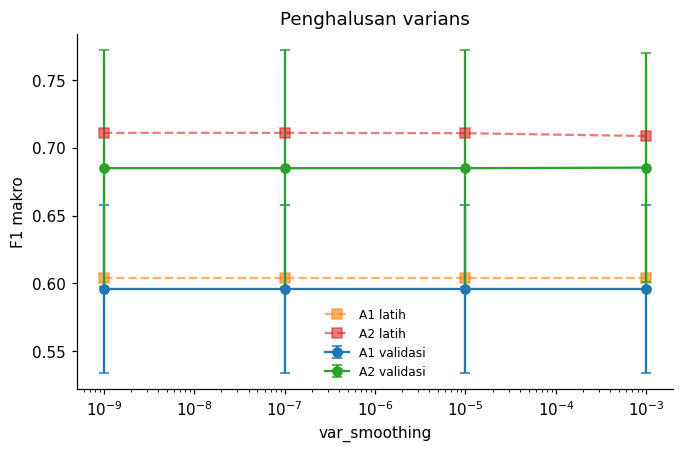

In [7]:
tuning_table = pd.concat({name: summary[["var_smoothing", "train_f1_mean", "val_f1_mean", "val_f1_sd", "val_acc_mean"]].set_index("var_smoothing") for name, summary in summaries.items()}, axis=1)
save_table(tuning_table.round(4), "tuning_table")
display(tuning_table.round(4))

fig, ax = plt.subplots(figsize=(7, 4.2))
for name, summary in summaries.items():
    ax.errorbar(summary["var_smoothing"], summary["val_f1_mean"], yerr=summary["val_f1_sd"], marker="o", capsize=3, label=f"{name} validasi")
    ax.plot(summary["var_smoothing"], summary["train_f1_mean"], marker="s", linestyle="--", alpha=0.6, label=f"{name} latih")
ax.set_xscale("log")
ax.set(xlabel="var_smoothing", ylabel="F1 makro", title="Penghalusan varians")
ax.legend(frameon=False, fontsize=8)
save_figure(fig, "var_smoothing_curve.png")
plt.show()

##### 4.4 Sebaran skor lipatan

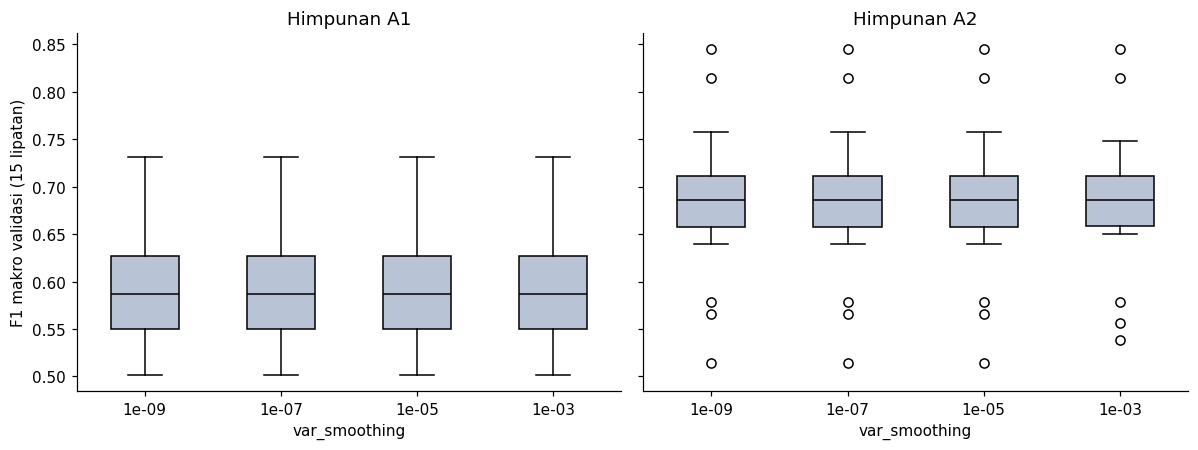

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (name, summary) in zip(axes, summaries.items()):
    data = [tuning_scores[name].loc[tuning_scores[name]["config_id"] == cid, "val_macro_f1"].to_numpy() for cid in summary.index]
    boxes = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": "black"})
    for patch in boxes["boxes"]:
        patch.set_facecolor("#B8C4D6")
    ax.set_xticks(range(1, len(data) + 1), [f"{v:.0e}" for v in summary["var_smoothing"]])
    ax.set_xlabel("var_smoothing")
    ax.set_title(f"Himpunan {name}")
axes[0].set_ylabel("F1 makro validasi (15 lipatan)")
fig.tight_layout()
save_figure(fig, "var_smoothing_boxplot.png")
plt.show()

##### 4.5 Pemilihan konfigurasi

Pemenang adalah nilai dengan rata-rata F1 makro validasi tertinggi. Jika sama pada empat desimal, dipilih `var_smoothing` yang lebih besar. Himpunan fitur mengikuti keputusan notebook 03.

In [9]:
best_config = {name: ev.select_best(summary, "neg_var_smoothing") for name, summary in summaries.items()}
best_params = {name: ev.params_from_row(best_config[name], PARAM_COLUMNS) for name in FEATURE_SETS}

winner_table = pd.DataFrame(
    {
        name: {
            "var_smoothing": best_params[name]["var_smoothing"],
            "F1 makro validasi": best_config[name]["val_f1_mean"],
            "SD": best_config[name]["val_f1_sd"],
            "F1 makro latih": best_config[name]["train_f1_mean"],
        }
        for name in FEATURE_SETS
    }
)
save_table(winner_table, "winner")
display(winner_table)
print("Himpunan fitur yang dievaluasi :", SELECTED_SET)
print("Parameter terpilih             :", best_params[SELECTED_SET])

,A1,A2
var_smoothing,0.001000,0.001000
F1 makro validasi,0.596007,0.685336
SD,0.062139,0.084303
F1 makro latih,0.604344,0.708634


Himpunan fitur yang dievaluasi : A1
Parameter terpilih             : {'var_smoothing': 0.001}


#### 5. Evaluasi Validasi Silang Model Terpilih

##### 5.1 Prediksi out-of-fold

In [10]:
oof = {}
for name in FEATURE_SETS:
    oof[name] = ev.cross_val_predictions(lambda n=name: make_model(best_params[n]), train, FEATURE_SETS[name])
    oof[name].to_csv(RESULTS_DIR / f"{PREFIX}_oof_{name}.csv", index=False)

oof_selected = oof[SELECTED_SET]
SELECTED_PARAMS = best_params[SELECTED_SET]
print("Himpunan fitur :", SELECTED_SET)
print("Parameter      :", SELECTED_PARAMS)
print("Baris OOF      :", len(oof_selected), f"({oof_selected['repeat'].nunique()} pengulangan)")

Himpunan fitur : A1
Parameter      : {'var_smoothing': 0.001}
Baris OOF      : 912 (3 pengulangan)


##### 5.2 Matriks konfusi

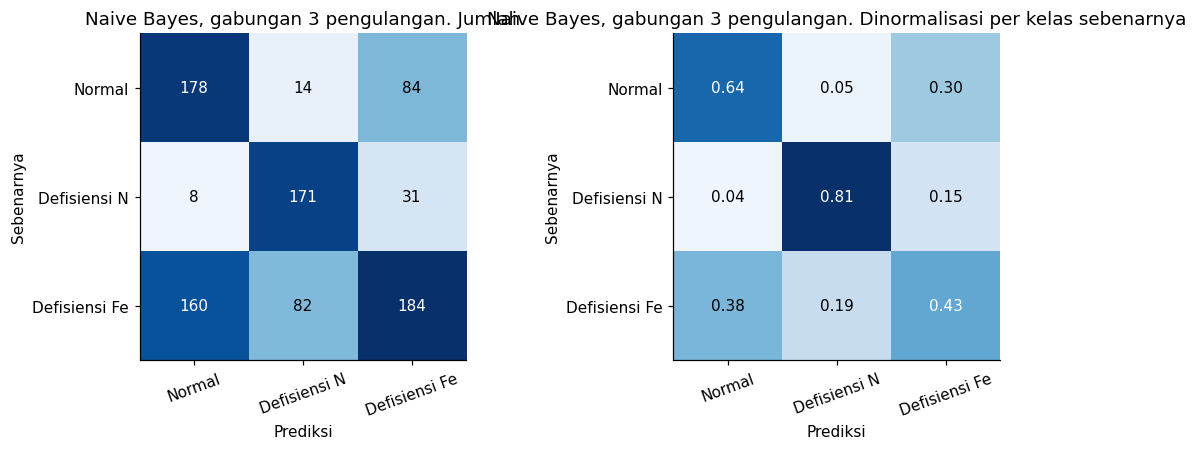

,Prediksi Normal,Prediksi Defisiensi N,Prediksi Defisiensi Fe
Sebenarnya Normal,59,4,28
Sebenarnya Defisiensi N,2,57,10
Sebenarnya Defisiensi Fe,53,27,61


In [11]:
pooled_counts = ev.confusion_counts(oof_selected["label"], oof_selected["pred"])
ev.plot_confusion(pooled_counts, title=f"{MODEL_LABEL}, gabungan 3 pengulangan.")
plt.gcf().tight_layout()
save_figure(plt.gcf(), "confusion_matrix.png")
plt.show()

confusion_table = pd.DataFrame(
    pooled_counts // oof_selected["repeat"].nunique(),
    index=[f"Sebenarnya {CLASS_LABEL_ID[c]}" for c in CLASSES],
    columns=[f"Prediksi {CLASS_LABEL_ID[c]}" for c in CLASSES],
)
save_table(confusion_table, "confusion_per_repeat")
display(confusion_table)

##### 5.3 Metrik per kelas dan skor lipatan

,precision,recall,f1,support
Normal,0.5145,0.6449,0.5723,276.0
Defisiensi N,0.6404,0.8143,0.7170,210.0
Defisiensi Fe,0.6154,0.4319,0.5076,426.0
Rata-rata makro,0.5901,0.6304,0.5990,912.0
Rata-rata berbobot,0.5906,0.5844,0.5754,912.0
Akurasi,NaN,NaN,0.5844,912.0


,mean,std,min,max
macro_f1,0.5960,0.0621,0.5018,0.7312
accuracy,0.5939,0.0650,0.5067,0.7500


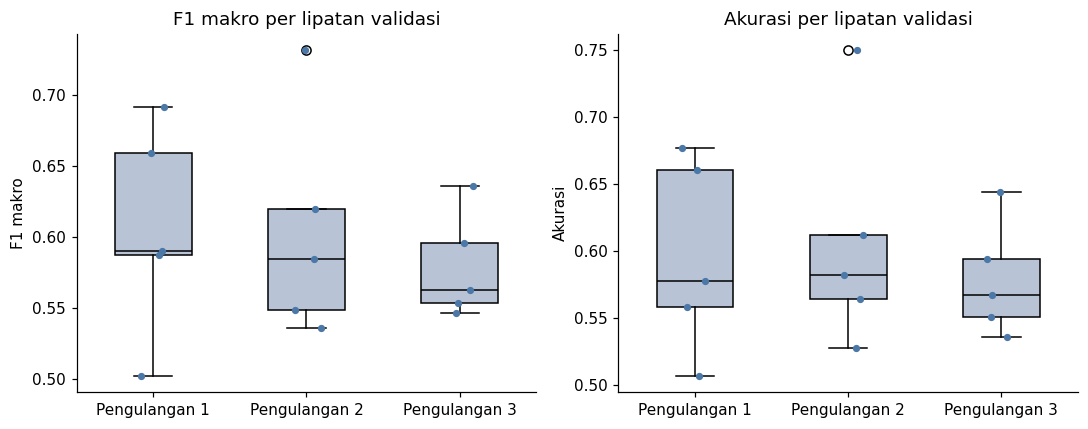

In [12]:
metric_table = ev.metrics_table(oof_selected["label"], oof_selected["pred"])
save_table(metric_table.round(4), "classification_metrics")
display(metric_table.round(4))

fold_table = ev.fold_scores(oof_selected)
fold_summary = fold_table[["macro_f1", "accuracy"]].agg(["mean", "std", "min", "max"]).T.round(4)
save_table(fold_summary, "fold_summary")
display(fold_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in zip(axes, ("macro_f1", "accuracy"), ("F1 makro", "Akurasi")):
    data = [fold_table.loc[fold_table["repeat"] == r, metric].to_numpy() for r in sorted(fold_table["repeat"].unique())]
    boxes = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": "black"})
    for patch in boxes["boxes"]:
        patch.set_facecolor("#B8C4D6")
    for i, values in enumerate(data, start=1):
        ax.scatter(np.full(len(values), i) + rng.uniform(-0.1, 0.1, len(values)), values, s=14, color="#4C78A8", zorder=3)
    ax.set_xticks(range(1, len(data) + 1), [f"Pengulangan {r}" for r in sorted(fold_table["repeat"].unique())])
    ax.set_ylabel(title)
    ax.set_title(f"{title} per lipatan validasi")
fig.tight_layout()
save_figure(fig, "fold_scores.png")
plt.show()

##### 5.4 Kurva ROC dan Precision-Recall

$$
\mathrm{TPR} = \frac{TP}{TP + FN}, \qquad \mathrm{FPR} = \frac{FP}{FP + TN}, \qquad \mathrm{AP} = \sum_{n} (R_n - R_{n-1})\, P_n
$$

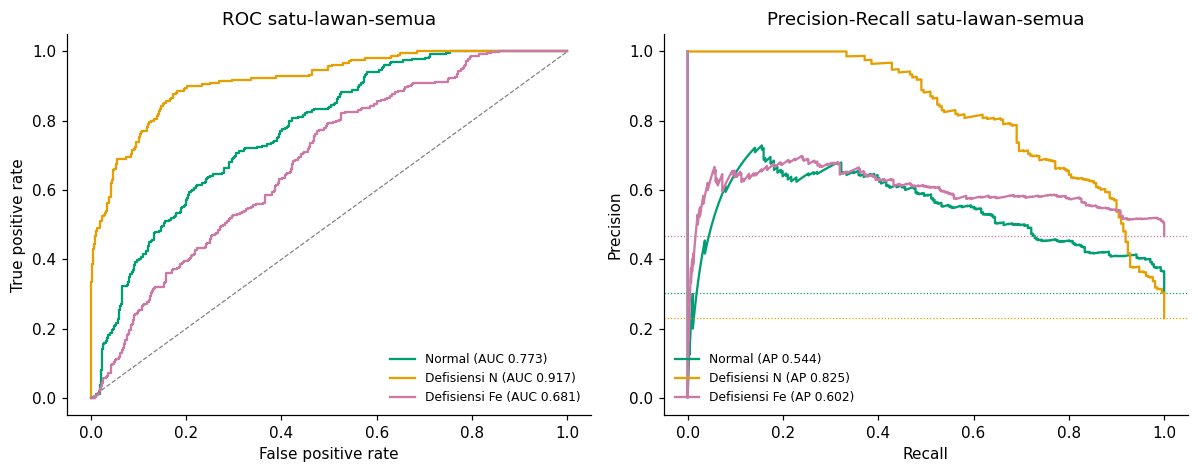

,AUC,AP,prevalensi
Normal,0.7728,0.5442,0.3026
Defisiensi N,0.9170,0.8249,0.2303
Defisiensi Fe,0.6810,0.6019,0.4671
Rata-rata makro,0.7903,0.6570,0.3333


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
curves = ev.plot_roc_pr(oof_selected, axes)
fig.tight_layout()
save_figure(fig, "roc_pr.png")
plt.show()

curve_table = pd.DataFrame({CLASS_LABEL_ID[k]: {"AUC": v["auc"], "AP": v["ap"], "prevalensi": v["prevalence"]} for k, v in curves.items()}).T
curve_table.loc["Rata-rata makro"] = curve_table.mean()
save_table(curve_table.round(4), "roc_pr_summary")
display(curve_table.round(4))

##### 5.5 Kurva pembelajaran

,train_files,train_f1,train_sd,val_f1,val_sd
fraction,,,,,
0.2,61.0,0.6570,0.1099,0.5790,0.1211
0.4,108.4,0.6416,0.0499,0.5744,0.0897
0.6,153.6,0.5727,0.0567,0.6023,0.0860
0.8,197.8,0.6136,0.0469,0.6007,0.0741
1.0,243.2,0.6014,0.0407,0.6059,0.0735


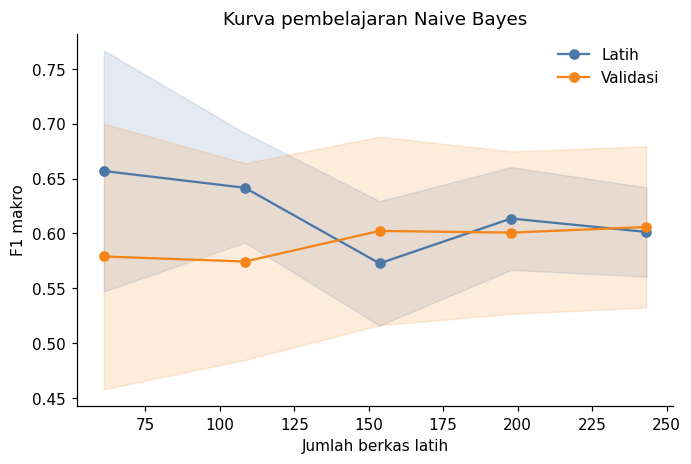

In [14]:
learning = ev.learning_curve(lambda: make_model(SELECTED_PARAMS), train, SELECTED_FEATURES, fractions=LEARNING_FRACTIONS, seed=SEED)
learning_summary = learning.groupby("fraction").agg(
    train_files=("train_files", "mean"),
    train_f1=("train_macro_f1", "mean"), train_sd=("train_macro_f1", "std"),
    val_f1=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std"),
)
save_table(learning_summary.round(4), "learning_curve")
display(learning_summary.round(4))

fig, ax = plt.subplots(figsize=(7, 4.4))
for column, sd, label, color in (("train_f1", "train_sd", "Latih", "#4C78A8"), ("val_f1", "val_sd", "Validasi", "#F58518")):
    ax.plot(learning_summary["train_files"], learning_summary[column], marker="o", color=color, label=label)
    ax.fill_between(learning_summary["train_files"], learning_summary[column] - learning_summary[sd], learning_summary[column] + learning_summary[sd], color=color, alpha=0.15)
ax.set(xlabel="Jumlah berkas latih", ylabel="F1 makro", title=f"Kurva pembelajaran {MODEL_LABEL}")
ax.legend(frameon=False)
save_figure(fig, "learning_curve.png")
plt.show()

##### 5.6 Pentingnya fitur (permutasi)

$$
\mathrm{PI}_j = F1_{\text{dasar}} - \frac{1}{R}\sum_{r=1}^{R} F1_{\text{acak}}^{(j, r)}
$$

,importance_mean,importance_sd
feature,,
Mean_R,0.1615,0.0786
Mean_G,0.0180,0.0258
Mean_B,-0.0065,0.0303


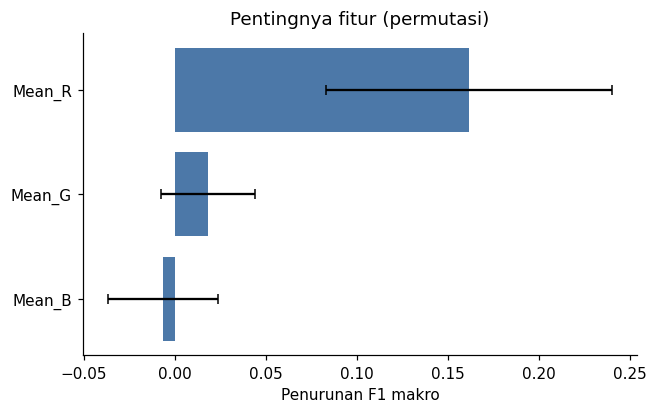

In [15]:
importance = ev.permutation_importance(lambda: make_model(SELECTED_PARAMS), train, SELECTED_FEATURES, n_repeats=PERMUTATION_REPEATS, seed=SEED)
save_table(importance.round(4), "permutation_importance")
display(importance.round(4))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ordered = importance.sort_values("importance_mean")
ax.barh(ordered.index, ordered["importance_mean"], xerr=ordered["importance_sd"], color="#4C78A8", capsize=3)
ax.set(xlabel="Penurunan F1 makro", title="Pentingnya fitur (permutasi)")
save_figure(fig, "permutation_importance.png")
plt.show()

##### 5.7 Galeri salah klasifikasi

,label,pred,jumlah
0,Defisiensi Fe,Defisiensi N,28
1,Defisiensi Fe,Normal,51
2,Defisiensi N,Defisiensi Fe,11
3,Defisiensi N,Normal,1
4,Normal,Defisiensi Fe,29
5,Normal,Defisiensi N,4


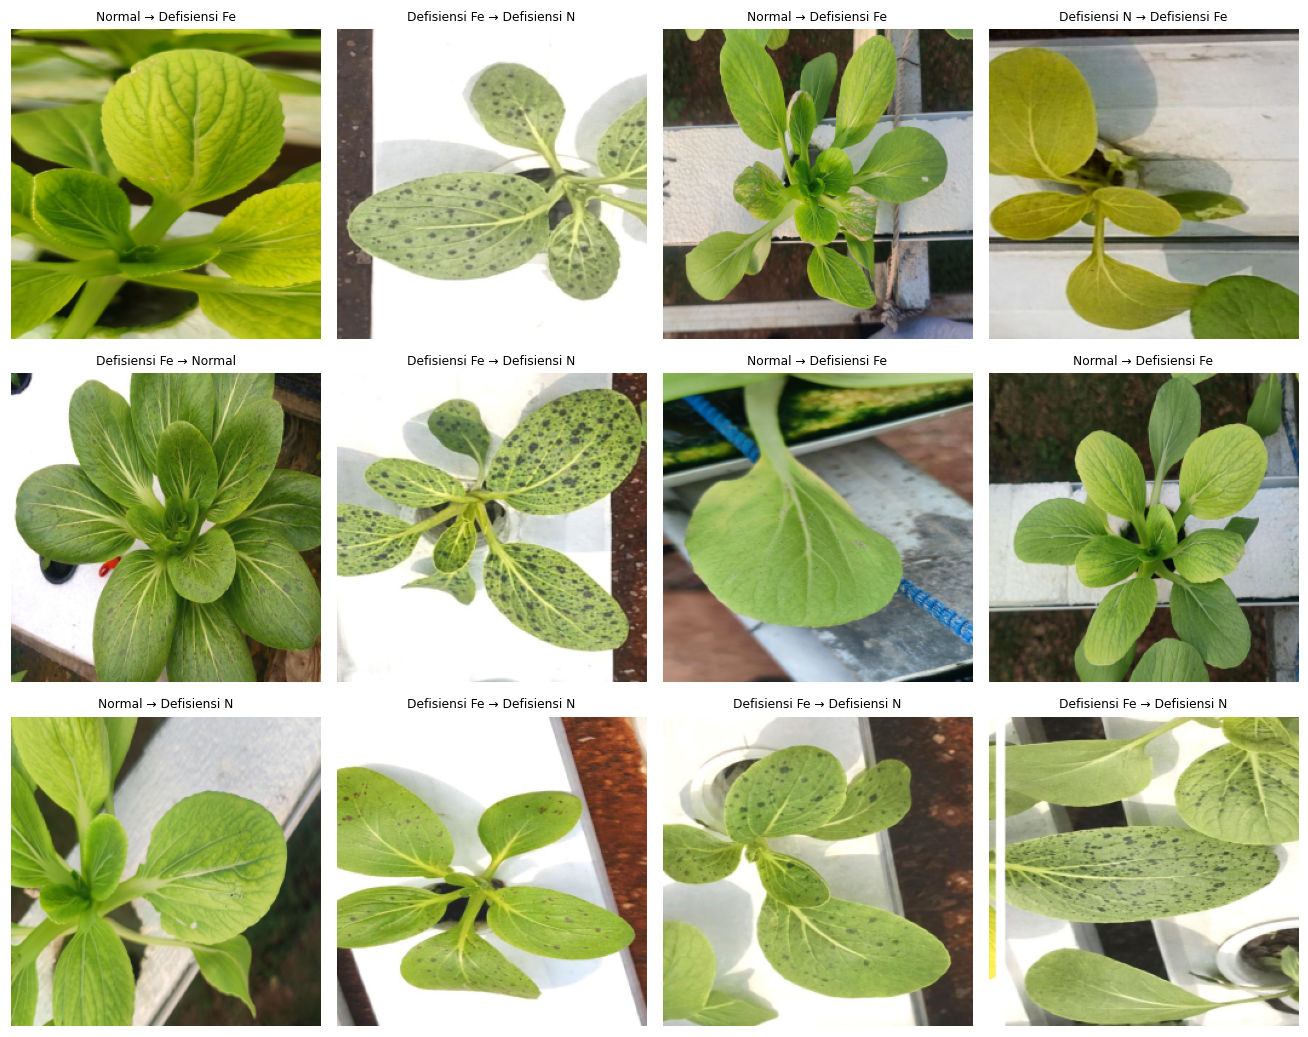

In [16]:
oof_selected = oof_selected.assign(correct=oof_selected["label"] == oof_selected["pred"])
errors = oof_selected[(oof_selected["repeat"] == 1) & (~oof_selected["correct"])]
error_pairs = errors.groupby(["label", "pred"]).size().rename("jumlah").reset_index()
error_pairs["label"] = error_pairs["label"].map(CLASS_LABEL_ID)
error_pairs["pred"] = error_pairs["pred"].map(CLASS_LABEL_ID)
save_table(error_pairs, "misclassified_pairs", index=False)
display(error_pairs)

fig = ev.plot_gallery(errors, RAW_DIR, max_items=GALLERY_SIZE, seed=SEED)
save_figure(fig, "misclassified_gallery.png")
plt.show()

##### 5.8 Interval kepercayaan bootstrap (resampling foto sumber)

$$
\hat{\theta}^{*(b)} = \theta\left(\{g_1^{*}, \dots, g_G^{*}\}\right), \qquad g_i^{*} \sim \mathrm{Uniform}(\mathcal{G}), \qquad \mathrm{CI}_{95\%} = \left[\hat{\theta}^{*}_{0{,}025},\ \hat{\theta}^{*}_{0{,}975}\right]
$$

,estimate,low,high
F1 makro,0.5990,0.5230,0.6578
Akurasi,0.5844,0.5148,0.6549
Recall Defisiensi N,0.8143,0.6780,0.9273
Recall Defisiensi Fe,0.4319,0.3765,0.4963
Recall Normal,0.6449,0.5307,0.7500


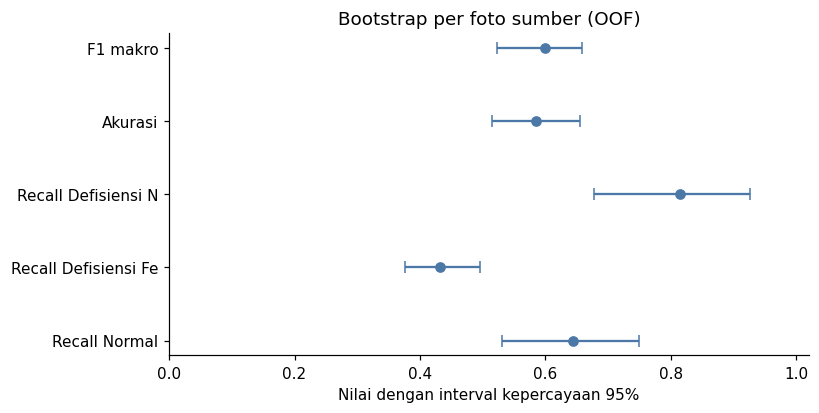

In [17]:
bootstrap_metrics = {
    "F1 makro": ev.fast_macro_f1,
    "Akurasi": ev.fast_accuracy,
    "Recall Defisiensi N": ev.fast_recall("n_deficiency"),
    "Recall Defisiensi Fe": ev.fast_recall("fe_deficiency"),
    "Recall Normal": ev.fast_recall("normal"),
}
bootstrap_rows = {name: ev.bootstrap_group_ci(oof_selected, metric, n_boot=N_BOOTSTRAP, seed=SEED) for name, metric in bootstrap_metrics.items()}
bootstrap_table = pd.DataFrame(bootstrap_rows).T[["estimate", "low", "high"]]
save_table(bootstrap_table.round(4), "bootstrap_ci")
display(bootstrap_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y_positions = np.arange(len(bootstrap_table))[::-1]
ax.errorbar(bootstrap_table["estimate"], y_positions, xerr=[bootstrap_table["estimate"] - bootstrap_table["low"], bootstrap_table["high"] - bootstrap_table["estimate"]], fmt="o", color="#4C78A8", capsize=4)
ax.set_yticks(y_positions, bootstrap_table.index)
ax.set(xlabel="Nilai dengan interval kepercayaan 95%", title="Bootstrap per foto sumber (OOF)")
ax.set_xlim(0, 1.02)
save_figure(fig, "bootstrap_ci.png")
plt.show()

##### 5.9 Perbandingan himpunan fitur A1 dan A2

In [18]:
comparison_rows = {}
for name in FEATURE_SETS:
    part = oof[name]
    folds = ev.fold_scores(part)
    comparison_rows[name] = {
        "parameter": str(best_params[name]),
        "F1 makro (rata-rata lipatan)": folds["macro_f1"].mean(),
        "SD lipatan": folds["macro_f1"].std(),
        "akurasi": folds["accuracy"].mean(),
        "recall Normal": ev.fast_recall("normal")(part["label"], part["pred"]),
        "recall Defisiensi N": ev.fast_recall("n_deficiency")(part["label"], part["pred"]),
        "recall Defisiensi Fe": ev.fast_recall("fe_deficiency")(part["label"], part["pred"]),
    }
feature_set_comparison = pd.DataFrame(comparison_rows)
save_table(feature_set_comparison, "feature_set_comparison")
display(feature_set_comparison)

,A1,A2
parameter,{'var_smoothing': 0.001},{'var_smoothing': 0.001}
F1 makro (rata-rata lipatan),0.596007,0.685336
SD lipatan,0.062139,0.084303
akurasi,0.593891,0.684429
recall Normal,0.644928,0.702899
recall Defisiensi N,0.814286,0.861905
recall Defisiensi Fe,0.431925,0.558685


#### 6. Analisis Khusus Naive Bayes

##### 6.1 Prior dan parameter Gaussian

In [19]:
X_full = train[SELECTED_FEATURES].to_numpy(dtype=float)
y_full = train["label"].to_numpy()
nb_model = make_model(SELECTED_PARAMS).fit(X_full, y_full, SELECTED_FEATURES, CLASSES)
nb = nb_model.estimator
order = [list(nb.classes_).index(c) for c in CLASSES]

prior_table = pd.DataFrame(
    {
        "berkas": train["label"].value_counts().reindex(CLASSES).to_numpy(),
        "prior P(c) setelah pembobotan": nb.class_prior_[order],
    },
    index=[CLASS_LABEL_ID[c] for c in CLASSES],
)
save_table(prior_table.round(4), "class_priors")
display(prior_table.round(4))

mean_table = pd.DataFrame(nb.theta_[order], index=[CLASS_LABEL_ID[c] for c in CLASSES], columns=SELECTED_FEATURES)
variance_table = pd.DataFrame(nb.var_[order], index=[CLASS_LABEL_ID[c] for c in CLASSES], columns=SELECTED_FEATURES)
parameter_table = pd.concat({"mean (mu)": mean_table, "varians (sigma^2)": variance_table}, axis=1)
save_table(parameter_table.round(3), "gaussian_parameters")
display(parameter_table.round(3))
print("Epsilon penghalusan varians :", nb.epsilon_)

,berkas,prior P(c) setelah pembobotan
Normal,92,0.3333
Defisiensi N,70,0.3333
Defisiensi Fe,142,0.3333


mean (mu)                  varians (sigma^2)                  
                 Mean_R   Mean_G  Mean_B            Mean_R   Mean_G   Mean_B
Normal          100.209  128.272  54.674           525.468  512.492  414.581
Defisiensi N    175.950  175.363  68.764           834.988  483.687  724.288
Defisiensi Fe   121.785  139.304  65.687           528.807  489.770  572.272

Epsilon penghalusan varians : 1.3780530374610456


##### 6.2 Sebaran fitur per kelas dan kurva Gaussian terpasang

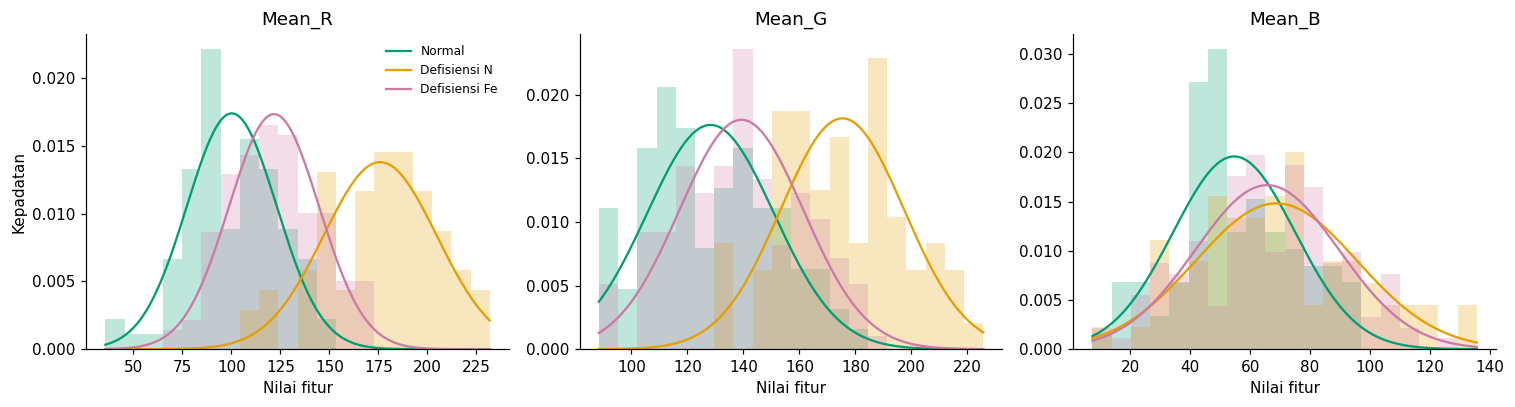

In [20]:
def gaussian_pdf(x, mean, variance):
    return np.exp(-((x - mean) ** 2) / (2.0 * variance)) / np.sqrt(2.0 * np.pi * variance)


n_features = len(SELECTED_FEATURES)
fig, axes = plt.subplots(1, n_features, figsize=(4.6 * n_features, 3.8)) if n_features <= 3 else plt.subplots(2, 3, figsize=(14, 7))
for ax, (j, feature) in zip(np.ravel(axes), enumerate(SELECTED_FEATURES)):
    low, high = train[feature].min(), train[feature].max()
    xs = np.linspace(low, high, 300)
    for c in CLASSES:
        values = train.loc[train["label"] == c, feature]
        ax.hist(values, bins=20, range=(low, high), density=True, color=CLASS_COLORS[c], alpha=0.25)
        ax.plot(xs, gaussian_pdf(xs, mean_table.loc[CLASS_LABEL_ID[c], feature], variance_table.loc[CLASS_LABEL_ID[c], feature]), color=CLASS_COLORS[c], label=CLASS_LABEL_ID[c])
    ax.set_title(feature)
    ax.set_xlabel("Nilai fitur")
np.ravel(axes)[0].set_ylabel("Kepadatan")
np.ravel(axes)[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "class_distributions.png")
plt.show()

##### 6.3 Pemeriksaan asumsi independen (korelasi antar fitur per kelas)

$$
r_{jk \mid c} = \frac{\mathrm{Cov}(x_j, x_k \mid c)}{\sigma_{j \mid c}\, \sigma_{k \mid c}}
$$

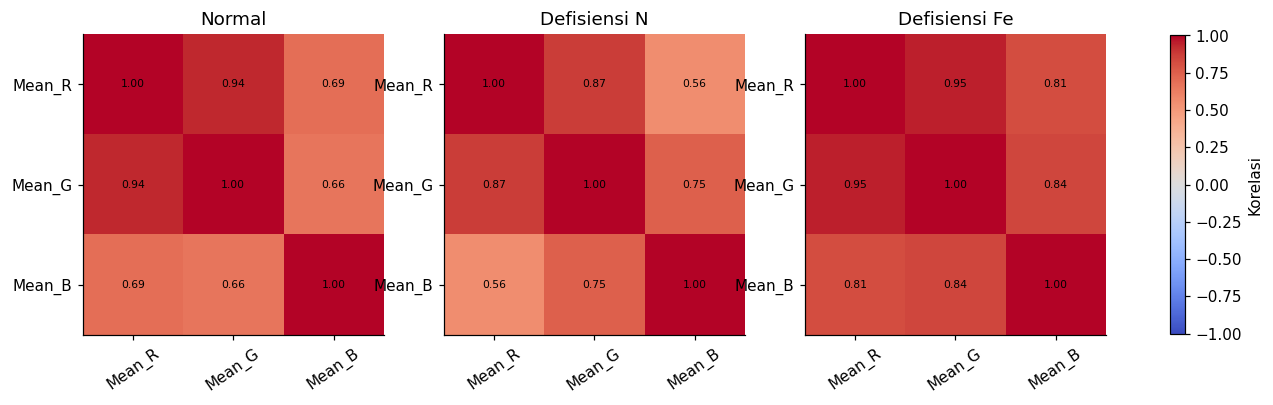

,rata-rata |korelasi| antar fitur
Normal,0.7617
Defisiensi N,0.7256
Defisiensi Fe,0.8668


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
mean_abs = {}
for ax, c in zip(axes, CLASSES):
    correlation = train.loc[train["label"] == c, SELECTED_FEATURES].corr()
    image = ax.imshow(correlation.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(n_features), SELECTED_FEATURES, rotation=35)
    ax.set_yticks(range(n_features), SELECTED_FEATURES)
    ax.set_title(CLASS_LABEL_ID[c])
    for i in range(n_features):
        for j in range(n_features):
            ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    off_diagonal = correlation.to_numpy()[~np.eye(n_features, dtype=bool)]
    mean_abs[CLASS_LABEL_ID[c]] = float(np.abs(off_diagonal).mean())
fig.colorbar(image, ax=axes, shrink=0.8, label="Korelasi")
save_figure(fig, "feature_correlation.png")
plt.show()

correlation_table = pd.Series(mean_abs, name="rata-rata |korelasi| antar fitur").to_frame()
save_table(correlation_table.round(4), "feature_correlation_summary")
display(correlation_table.round(4))

##### 6.4 Wilayah keputusan dua dimensi

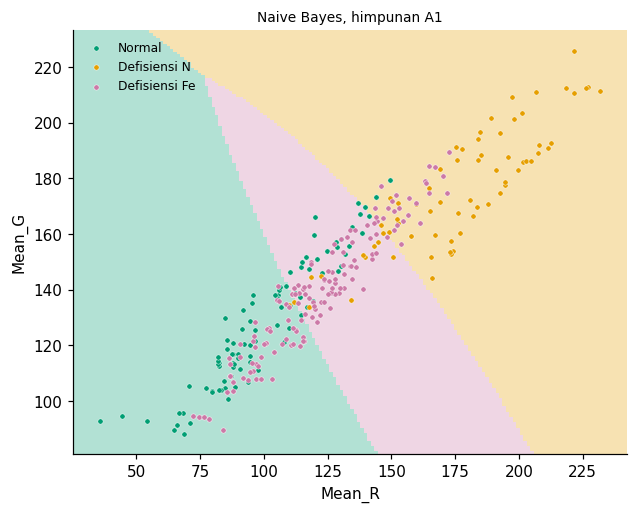

In [22]:
pair = ev.top_feature_pair(importance)
fig, ax = plt.subplots(figsize=(6.5, 5))
ev.plot_decision_regions(nb_model, train, SELECTED_FEATURES, pair, ax, title=f"Naive Bayes, himpunan {SELECTED_SET}")
ax.legend(frameon=False, fontsize=8)
save_figure(fig, "decision_regions.png")
plt.show()

##### 6.5 Ringkasan khusus Naive Bayes

In [23]:
MODEL_SPECIFIC = {
    "class_priors_weighted": {c: float(nb.class_prior_[order][i]) for i, c in enumerate(CLASSES)},
    "epsilon": float(nb.epsilon_),
    "means": mean_table.rename(index={v: k for k, v in CLASS_LABEL_ID.items()}).round(4).to_dict(orient="index"),
    "variances": variance_table.rename(index={v: k for k, v in CLASS_LABEL_ID.items()}).round(4).to_dict(orient="index"),
    "mean_abs_feature_correlation": mean_abs,
    "decision_region_features": list(pair),
}
print(json.dumps(MODEL_SPECIFIC["class_priors_weighted"], indent=2))

{
  "normal": 0.3333333333333333,
  "n_deficiency": 0.33333333333333337,
  "fe_deficiency": 0.33333333333333337
}


#### 7. Model Akhir dan Waktu Komputasi

##### 7.1 Pelatihan pada seluruh data latih

In [24]:
X_selected = train[SELECTED_FEATURES].to_numpy(dtype=float)
y_selected = train["label"].to_numpy()

final_model = make_model(SELECTED_PARAMS).fit(X_selected, y_selected, SELECTED_FEATURES, CLASSES)
train_pred = final_model.predict(X_selected)

print("Parameter      :", SELECTED_PARAMS)
print("F1 makro latih :", round(ev.macro_f1(y_selected, train_pred), 4))
print("Akurasi latih  :", round(float(np.mean(train_pred == y_selected)), 4))

Parameter      : {'var_smoothing': 0.001}
F1 makro latih : 0.5976
Akurasi latih  : 0.5822


##### 7.2 Waktu komputasi

In [25]:
preprocessing_timing = pd.read_csv(TABLES_DIR / "01_timing_per_stage.csv", index_col=0)
PREPROCESSING_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "rata-rata (ms)"])
PREPROCESSING_SD_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "simpangan baku (ms)"])

fit_timing = ev.time_calls(lambda: make_model(SELECTED_PARAMS).fit(X_selected, y_selected, SELECTED_FEATURES, CLASSES), repeats=TRAIN_TIMING_REPEATS)
sample_rows = [X_selected[i : i + 1] for i in range(len(X_selected))]
predict_timing = ev.time_single_predictions(lambda i: final_model.predict(sample_rows[i]), len(X_selected), repeats=PREDICT_TIMING_REPEATS)

timing_rows = [
    {"pengukuran": "Praproses per citra", "nilai": PREPROCESSING_MS, "simpangan_baku": PREPROCESSING_SD_MS, "satuan": "ms"},
    {"pengukuran": "Pelatihan model akhir", "nilai": fit_timing["mean"], "simpangan_baku": fit_timing["sd"], "satuan": "detik"},
]
for name, seconds in tuning_seconds.items():
    timing_rows.append({"pengukuran": f"Penalaan {name} ({len(grid)} konfigurasi x 15 lipatan)", "nilai": seconds, "simpangan_baku": np.nan, "satuan": "detik"})
timing_rows.append({"pengukuran": "Prediksi per sampel", "nilai": predict_timing["mean_ms"], "simpangan_baku": predict_timing["sd_ms"], "satuan": "ms"})
timing_table = pd.DataFrame(timing_rows).set_index("pengukuran")
save_table(timing_table.round(4), "compute_time")
display(timing_table.round(4))

,nilai,simpangan_baku,satuan
pengukuran,,,
Praproses per citra,7.9350,6.1550,ms
Pelatihan model akhir,0.0018,0.0004,detik
Penalaan A1 (4 konfigurasi x 15 lipatan),0.1855,NaN,detik
Penalaan A2 (4 konfigurasi x 15 lipatan),0.1934,NaN,detik
Prediksi per sampel,0.0719,0.0088,ms


#### 8. Penyimpanan Hasil

##### 8.1 Berkas hasil dan model

In [26]:
artifact_path = MODELS_DIR / f"{PREFIX}_candidate.joblib"
joblib.dump(final_model.estimator, artifact_path)

results = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "model": PREFIX,
    "seed": SEED,
    "libraries": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "hardware": HARDWARE,
    "data": {"train_rows": int(len(train)), "train_groups": int(train["source_group"].nunique()), "fold_columns": list(ev.FOLD_COLUMNS)},
    "grid": {"configurations": int(len(grid))},
    "feature_set": {"selected": SELECTED_SET, "features": SELECTED_FEATURES, "source": "03_c45_results.json"},
    "best_config": {
        name: {
            "params": best_params[name],
            "val_macro_f1_mean": as_float(best_config[name]["val_f1_mean"]),
            "val_macro_f1_sd": as_float(best_config[name]["val_f1_sd"]),
            "train_macro_f1_mean": as_float(best_config[name]["train_f1_mean"]),
        }
        for name in FEATURE_SETS
    },
    "selected": {
        "feature_set": SELECTED_SET,
        "params": SELECTED_PARAMS,
        "oof_metrics": {
            "macro_f1_fold_mean": float(fold_table["macro_f1"].mean()),
            "macro_f1_fold_sd": float(fold_table["macro_f1"].std()),
            "accuracy_fold_mean": float(fold_table["accuracy"].mean()),
            "per_class_recall": {c: float(ev.fast_recall(c)(oof_selected["label"], oof_selected["pred"])) for c in CLASSES},
        },
        "bootstrap_95ci": {name: {k: float(v) for k, v in row.items() if k in ("estimate", "low", "high")} for name, row in bootstrap_rows.items()},
    },
    "model_specific": MODEL_SPECIFIC,
    "compute": {
        "preprocessing_ms_per_image": {"mean": PREPROCESSING_MS, "sd": PREPROCESSING_SD_MS},
        "final_train_seconds": fit_timing,
        "tuning_seconds": tuning_seconds,
        "predict_ms_per_sample": predict_timing,
    },
    "artifacts": {"model": str(artifact_path.relative_to(ML_DIR)), "oof": [f"reports/results/{PREFIX}_oof_{name}.csv" for name in FEATURE_SETS]},
}
results_path = RESULTS_DIR / f"{PREFIX}_results.json"
results_path.write_text(json.dumps(results, indent=2, default=str), encoding="utf-8")
print("Disimpan :", results_path)
print("Disimpan :", artifact_path, f"({artifact_path.stat().st_size} byte)")

Disimpan : D:\LARAGON\www\nutrify\ml\reports\results\05_naive_bayes_results.json
Disimpan : D:\LARAGON\www\nutrify\ml\models\candidates\05_naive_bayes_candidate.joblib (1087 byte)


##### 8.2 Ringkasan akhir

In [27]:
final_summary = pd.DataFrame(
    [
        ("Himpunan fitur", SELECTED_SET),
        ("Parameter", str(SELECTED_PARAMS)),
        ("F1 makro validasi (rata-rata 15 lipatan)", round(results["selected"]["oof_metrics"]["macro_f1_fold_mean"], 4)),
        ("SD F1 makro lipatan", round(results["selected"]["oof_metrics"]["macro_f1_fold_sd"], 4)),
        ("Recall Normal", round(results["selected"]["oof_metrics"]["per_class_recall"]["normal"], 4)),
        ("Recall Defisiensi N", round(results["selected"]["oof_metrics"]["per_class_recall"]["n_deficiency"], 4)),
        ("Recall Defisiensi Fe", round(results["selected"]["oof_metrics"]["per_class_recall"]["fe_deficiency"], 4)),
        ("Prediksi per sampel (ms)", round(predict_timing["mean_ms"], 4)),
    ],
    columns=["item", "nilai"],
)
save_table(final_summary, "final_summary", index=False)
display(final_summary)

,item,nilai
0,Himpunan fitur,A1
1,Parameter,{'var_smoothing': 0.001}
2,F1 makro validasi (rata-rata 15 lipatan),0.596
3,SD F1 makro lipatan,0.0621
4,Recall Normal,0.6449
5,Recall Defisiensi N,0.8143
6,Recall Defisiensi Fe,0.4319
7,Prediksi per sampel (ms),0.0719
